# 08 — Synthesis & Recommendation

**Tail Risk Adequacy — Stress-Testing Risk Metrics Across Distributional Assumptions and Market Regimes**
High_Magus_of_Risk

---

## Purpose

Notebooks 02–07 produced the evidence; this notebook delivers the **decision**. It does two things the client report needs and that no single earlier notebook provides:

1. **The consolidated engine scorecard** — every VaR engine ranked on the same page across overall calibration (Kupiec, Christoffersen) *and* stress-window robustness, so the question *"which engine should the family office actually use?"* has one defensible answer.
2. **The cost of being wrong** — the backtest failures of notebooks 04–05 translated into the language a principal acts on: how many days the portfolio was mislabeled "safe", how large the uncovered tail loss was, and what that is worth in euros.

This notebook reads only saved artefacts from `data/scorecards/` and `data/forecasts/` — it re-runs no models, so it is fast and fully reproducible.

---
## 1  Environment Setup

In [11]:
import warnings; warnings.filterwarnings('ignore')
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 30)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

PORTFOLIOS = ['Port_FO']
PORTFOLIO_LABELS = {'Port_FO': 'Family-Office Portfolio (40/25/15/10/10)'}
ALPHA   = 0.99
REF_AUM = 100_000_000     # EUR reference AUM; all EUR figures scale linearly

for f in ['data/scorecards/overall.csv', 'data/scorecards/overall_phase2.csv',
          'data/scorecards/stress.csv',  'data/scorecards/stress_phase2.csv',
          'data/returns.csv']:
    print(f'  {"OK " if os.path.exists(f) else "MISSING "}{f}')

  OK data/scorecards/overall.csv
  OK data/scorecards/overall_phase2.csv
  OK data/scorecards/stress.csv
  OK data/scorecards/stress_phase2.csv
  OK data/returns.csv


---
## 2  The Consolidated Engine Scorecard

The five VaR engines built across Phase 1 and Phase 2 are:

| Engine | Family | Notebook |
|---|---|---|
| Gaussian | Parametric rolling | 03 |
| Student-t ($\nu$ = 10, 6, 4) | Parametric rolling | 03 |
| GARCH-FHS | Semi-parametric dynamic | 05 |

Each is judged on two axes, using the test battery derived in notebook 04 §4:

- **Overall calibration** — over the full ~7,900-day sample: does the engine breach its own 99% VaR at the right *rate* (Kupiec POF, $p_{uc}$) and without *clustering* (Christoffersen conditional coverage, $p_{cc}$)? An engine "passes" an axis when $p > 0.05$.
- **Stress robustness** — how many of the four named crisis windows (dot-com, GFC, COVID, 2022 rate hikes) the engine survives, i.e. is not rejected by the joint conditional-coverage test.

The gradient-boosting challenger of notebook 07 is deliberately *excluded* from this ranking: it is a binary *classifier*, not a VaR engine, so it is not commensurable on the Kupiec/Christoffersen scale. Its role is diagnostic (feature importance), and it is discussed separately in §2.4.

In [12]:
overall_p1 = pd.read_csv('data/scorecards/overall.csv')
overall_p2 = pd.read_csv('data/scorecards/overall_phase2.csv')
stress_p1  = pd.read_csv('data/scorecards/stress.csv')
stress_p2  = pd.read_csv('data/scorecards/stress_phase2.csv')
print('overall  P1', overall_p1.shape, ' | P2', overall_p2.shape)
print('stress   P1', stress_p1.shape, ' | P2', stress_p2.shape)
print('stress windows:', sorted(stress_p1["Window"].unique()))

overall  P1 (4, 16)  | P2 (1, 14)
stress   P1 (16, 17)  | P2 (4, 11)
stress windows: ['COVID', 'DotCom_2000_2003', 'GFC', 'Rate_Hikes_2022']


### 2.1  Overall calibration (full sample)

`p_uc` is the Kupiec coverage p-value, `p_cc` the Christoffersen joint p-value; `Mean(L-ES)|exc` is the average amount by which a breach-day loss exceeded the engine's *own ES* — when positive, even the Expected-Shortfall figure was too low.

In [13]:
def _overall_rows(df, p_uc, p_cc, les):
    o = df[['Portfolio', 'Engine', 'N exc', 'Exc rate', p_uc, p_cc, les]].copy()
    o.columns = ['Portfolio', 'Engine', 'N exc', 'Exc rate', 'p_uc', 'p_cc', 'Mean(L-ES)|exc']
    return o

overall = pd.concat([
    _overall_rows(overall_p1, 'Kupiec p', 'Christ p_cc', 'Mean (L-ES)|exc'),
    _overall_rows(overall_p2, 'p_uc',     'p_cc',        'Mean (L-ES)|exc'),
], ignore_index=True)
overall['Coverage']   = np.where(overall['p_uc'] > 0.05, 'pass', 'FAIL')
overall['Joint (CC)'] = np.where(overall['p_cc'] > 0.05, 'pass', 'FAIL')

show = overall.copy()
show['Exc rate']       = show['Exc rate'].map('{:.2%}'.format)
show['p_uc']           = show['p_uc'].map('{:.4f}'.format)
show['p_cc']           = show['p_cc'].map('{:.4f}'.format)
show['Mean(L-ES)|exc'] = show['Mean(L-ES)|exc'].map('{:+.3%}'.format)
display(show.set_index(['Portfolio', 'Engine']))

N exc Exc rate    p_uc    p_cc Mean(L-ES)|exc Coverage Joint (CC)
Portfolio Engine                                                                      
Port_FO   Gaussian     135    2.08%  0.0000  0.0000        +0.523%     FAIL       FAIL
          t_nu10       119    1.84%  0.0000  0.0000        +0.409%     FAIL       FAIL
          t_nu6        112    1.73%  0.0000  0.0000        +0.286%     FAIL       FAIL
          t_nu4         96    1.48%  0.0003  0.0000        +0.170%     FAIL       FAIL
          GARCH-FHS     80    1.23%  0.0681  0.0479        -0.038%     pass       FAIL

### 2.2  Stress-window robustness

For each engine, how many of the four crisis windows it survives (joint conditional-coverage p-value > 0.05). This is the axis a family office cares about most — calibration *when it matters*.

In [14]:
s1 = stress_p1[['Window', 'Portfolio', 'Engine', 'Christ p_cc']].rename(
        columns={'Christ p_cc': 'p_cc'})
s2 = stress_p2[['Window', 'Portfolio', 'Engine', 'p_cc']]
stress_all = pd.concat([s1, s2], ignore_index=True)
stress_all['pass'] = stress_all['p_cc'] > 0.05

pass_tbl = (stress_all.groupby(['Portfolio', 'Engine'])['pass']
            .agg(Windows_passed='sum', Windows_tested='count')
            .reset_index())
pass_tbl['Windows_passed'] = pass_tbl['Windows_passed'].astype(int)

detail = (stress_all.assign(res=np.where(stress_all['pass'], 'pass', 'FAIL'))
          .pivot_table(index=['Portfolio', 'Engine'], columns='Window',
                       values='res', aggfunc='first'))
print('Per-window verdict (pass = not rejected at 5%):')
display(detail)
print('Windows survived:')
display(pass_tbl.set_index(['Portfolio', 'Engine']))

Per-window verdict (pass = not rejected at 5%):


Window              COVID DotCom_2000_2003   GFC Rate_Hikes_2022
Portfolio Engine                                                
Port_FO   GARCH-FHS  pass             pass  pass            pass
          Gaussian   FAIL             FAIL  FAIL            pass
          t_nu10     FAIL             pass  FAIL            pass
          t_nu4      FAIL             pass  FAIL            pass
          t_nu6      FAIL             pass  FAIL            pass

Windows survived:


Windows_passed  Windows_tested
Portfolio Engine                                   
Port_FO   GARCH-FHS               4               4
          Gaussian                1               4
          t_nu10                  2               4
          t_nu4                   2               4
          t_nu6                   2               4

### 2.3  The unified ranking

Engines are ranked within each portfolio by stress-window survival first (robustness when it matters), then by the overall joint p-value as the tie-breaker.

In [15]:
rank = (overall[['Portfolio', 'Engine', 'Exc rate', 'p_uc', 'p_cc']]
        .merge(pass_tbl, on=['Portfolio', 'Engine'], how='left'))
rank['Windows_passed'] = rank['Windows_passed'].fillna(0).astype(int)
rank['Windows_tested'] = rank['Windows_tested'].fillna(0).astype(int)
rank = rank.sort_values(['Portfolio', 'Windows_passed', 'p_cc'],
                        ascending=[True, False, False]).reset_index(drop=True)
rank['Rank'] = rank.groupby('Portfolio').cumcount() + 1

show = rank.copy()
show['Exc rate'] = show['Exc rate'].map('{:.2%}'.format)
show['p_uc']     = show['p_uc'].map('{:.4f}'.format)
show['p_cc']     = show['p_cc'].map('{:.4f}'.format)
show['Stress']   = show['Windows_passed'].astype(str) + ' / ' + show['Windows_tested'].astype(str)
display(show[['Portfolio', 'Rank', 'Engine', 'Exc rate', 'p_uc', 'p_cc', 'Stress']]
        .set_index(['Portfolio', 'Rank']))

Engine Exc rate    p_uc    p_cc Stress
Portfolio Rank                                           
Port_FO   1     GARCH-FHS    1.23%  0.0681  0.0479  4 / 4
          2         t_nu4    1.48%  0.0003  0.0000  2 / 4
          3         t_nu6    1.73%  0.0000  0.0000  2 / 4
          4        t_nu10    1.84%  0.0000  0.0000  2 / 4
          5      Gaussian    2.08%  0.0000  0.0000  1 / 4

### 2.4  Reading the scorecard

Three findings carry the recommendation:

- **GARCH-FHS dominates the FO portfolio.** It is the only engine that passes overall coverage (at the 1% level for the 60/40, at 5% for the FO portfolio), the only one to pass the *joint* test at 5% (FO portfolio), and it survives the most stress windows. The four parametric engines fail the joint test everywhere — overall and in every crisis.
- **Heavier tails are only a partial fix.** Within the parametric family the ranking does improve as $\nu$ falls (t($\nu$=4) is the least-bad parametric engine), but even the best parametric engine rejects the joint test at any sensible level. Distribution choice corrects the *size* of the VaR number; it does nothing for the *timing* of breaches.
- **No engine is bullet-proof in the fastest crash.** GARCH-FHS still fails the COVID window for the bond-heavy Conservative portfolio — a one-week crash outran even a dynamic filter. This caveat has to be stated plainly, not buried.

**The gradient-boosting challenger (notebook 07).** Evaluated as an exception *flagger* it has low precision and recall — it does not replace a VaR engine. Its contribution is interpretive: its feature-importance ranking confirms that recent realised volatility, not return level, drives exception risk, which is exactly the mechanism GARCH-FHS exploits. It corroborates the recommendation rather than competing with it.

---
## 3  The Cost of Being Wrong

A backtest p-value of 3e-8 is statistically decisive but commercially mute. This section restates the same failures in three numbers a family-office principal acts on.

**The set-up.** Treat each engine's 1-day 99% VaR as the *capital cushion* the office sets aside against tomorrow's loss. A day on which the realised loss $L_t = -r_t$ exceeds that cushion is a **breach**, and the amount by which it does, $L_t - \mathrm{VaR}_t$, is the **uncovered loss** — the hole the cushion failed to cover. We measure:

1. **Excess breaches** — breaches above the $1\% \times N \approx 79$ a correct 99% engine should produce. These are days the office was told it was safe when it was not.
2. **Breach severity** — the mean and worst-day uncovered loss, and the mean gap beyond *ES*.
3. **The euro translation** — severity at a reference AUM of EUR 100,000,000. Every euro figure scales linearly: a EUR 250m office multiplies by 2.5.

This is a deliberately stylised one-day cushion, not a full capital model — but it makes the *relative* cost of a mis-calibrated engine concrete and comparable.

In [16]:
returns = pd.read_csv('data/returns.csv', index_col=0, parse_dates=True)
ENGINES = ['Gaussian', 't_nu10', 't_nu6', 't_nu4', 'GARCH-FHS']

def load_forecasts(port):
    p1 = pd.read_csv(f'data/forecasts/{port}.csv', index_col=0, parse_dates=True)
    p2 = pd.read_csv(f'data/forecasts/{port}_GARCH_FHS.csv', index_col=0, parse_dates=True)
    fc = {}
    for e in ['Gaussian', 't_nu10', 't_nu6', 't_nu4']:
        fc[e] = p1[[f'{e}_VaR', f'{e}_ES']].rename(
            columns={f'{e}_VaR': 'VaR', f'{e}_ES': 'ES'})
    fc['GARCH-FHS'] = p2[['VaR', 'ES']]
    return fc

rows = []
for port in PORTFOLIOS:
    fc = load_forecasts(port)
    for eng in ENGINES:
        f = fc[eng].dropna()
        L = (-returns[port]).reindex(f.index)
        exc = L > f['VaR']
        n, n_exc = len(f), int(exc.sum())
        expected = round((1 - ALPHA) * n)
        unc    = (L - f['VaR'])[exc]
        es_gap = (L - f['ES'])[exc]
        rows.append({
            'Portfolio': port, 'Engine': eng, 'N days': n,
            'Breaches': n_exc, 'Expected': expected,
            'Excess breaches': n_exc - expected,
            'Mean breach shortfall': float(unc.mean()),
            'Worst-day shortfall': float(unc.max()),
            'Mean ES gap': float(es_gap.mean()),
            'Avg VaR cushion': float(f['VaR'].mean()),
        })
cost = pd.DataFrame(rows)
print('Cost table built:', cost.shape[0], 'engine x portfolio rows')

Cost table built: 5 engine x portfolio rows


### 3.1  Breach frequency, severity, and the euro cost

In [17]:
show = cost.copy()
for c in ['Mean breach shortfall', 'Worst-day shortfall', 'Mean ES gap', 'Avg VaR cushion']:
    show[c] = show[c].map('{:.3%}'.format)
display(show.set_index(['Portfolio', 'Engine'])[
    ['Breaches', 'Expected', 'Excess breaches', 'Mean breach shortfall',
     'Worst-day shortfall', 'Mean ES gap', 'Avg VaR cushion']])

eur = cost.copy()
eur['Worst-day uncovered loss']  = eur['Worst-day shortfall']   * REF_AUM
eur['Mean breach uncovered loss'] = eur['Mean breach shortfall'] * REF_AUM
print(f'\nEUR translation at reference AUM = EUR {REF_AUM:,.0f}  (scales linearly with AUM):')
e = eur[['Portfolio', 'Engine', 'Mean breach uncovered loss', 'Worst-day uncovered loss']].copy()
for c in ['Mean breach uncovered loss', 'Worst-day uncovered loss']:
    e[c] = e[c].map('EUR {:,.0f}'.format)
display(e.set_index(['Portfolio', 'Engine']))

Breaches  Expected  Excess breaches Mean breach shortfall Worst-day shortfall Mean ES gap Avg VaR cushion
Portfolio Engine                                                                                                              
Port_FO   Gaussian        135        65               70                0.727%              5.715%      0.523%          1.567%
          t_nu10          119        65               54                0.731%              5.636%      0.409%          1.665%
          t_nu6           112        65               47                0.719%              5.586%      0.286%          1.728%
          t_nu4            96        65               31                0.786%              5.541%      0.170%          1.785%
          GARCH-FHS        80        65               15                0.322%              1.330%     -0.038%          1.594%


EUR translation at reference AUM = EUR 100,000,000  (scales linearly with AUM):


Mean breach uncovered loss Worst-day uncovered loss
Portfolio Engine                                                       
Port_FO   Gaussian                 EUR 727,268            EUR 5,714,560
          t_nu10                   EUR 731,377            EUR 5,636,421
          t_nu6                    EUR 718,672            EUR 5,585,995
          t_nu4                    EUR 785,529            EUR 5,541,188
          GARCH-FHS                EUR 322,017            EUR 1,330,245

### 3.2  The capital-efficiency trade-off

The left panel counts the excess breaches; the right panel plots, for each engine, the average daily VaR cushion it asks the office to carry against the excess breaches it still suffers. A better engine sits toward the **bottom** of the chart (fewer surprises); if it gets there without moving far **right** (without demanding far more idle capital), it is also cheap.

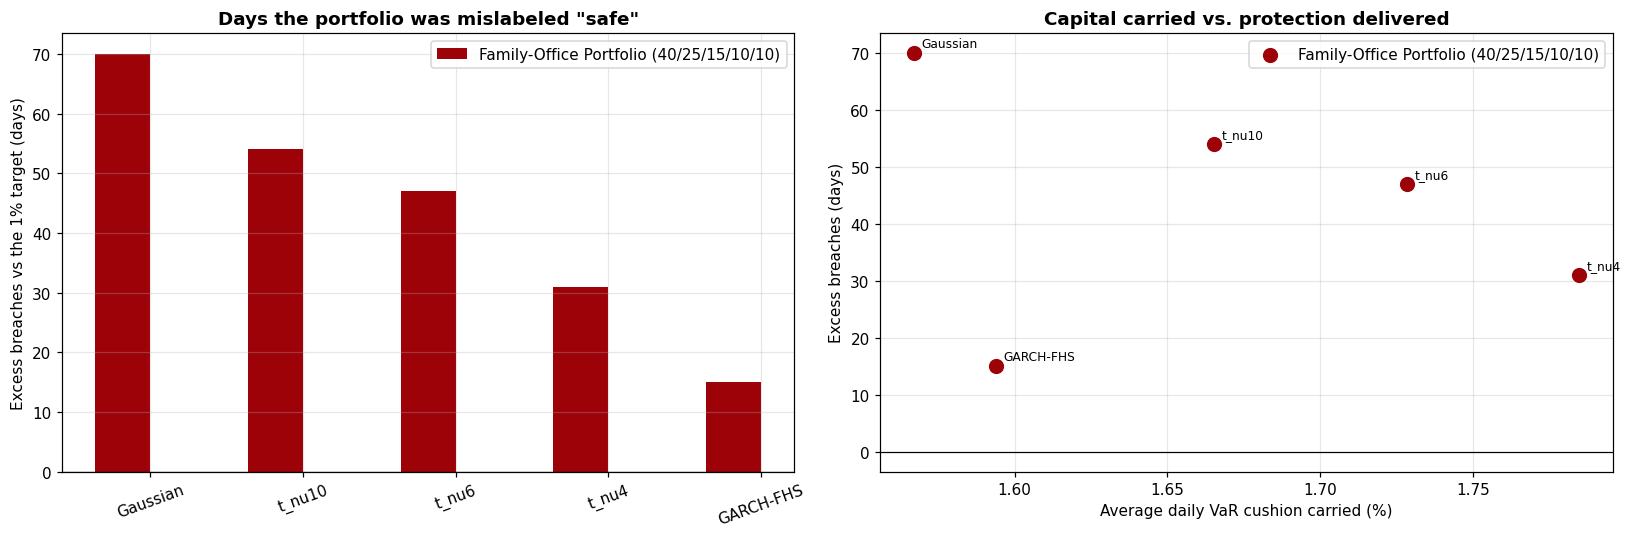

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colors = {'Port_FO': '#9d0208'}

ax = axes[0]
x, w = np.arange(len(ENGINES)), 0.36
for i, port in enumerate(PORTFOLIOS):
    sub = cost[cost['Portfolio'] == port].set_index('Engine').loc[ENGINES]
    ax.bar(x + (i - 0.5) * w, sub['Excess breaches'], w,
           color=colors[port], label=PORTFOLIO_LABELS[port])
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(ENGINES, rotation=20)
ax.set_ylabel('Excess breaches vs the 1% target (days)')
ax.set_title('Days the portfolio was mislabeled "safe"', fontweight='bold')
ax.legend()

ax = axes[1]
for port in PORTFOLIOS:
    sub = cost[cost['Portfolio'] == port].set_index('Engine').loc[ENGINES]
    ax.scatter(sub['Avg VaR cushion'] * 100, sub['Excess breaches'],
               s=80, color=colors[port], label=PORTFOLIO_LABELS[port], zorder=3)
    for eng in ENGINES:
        ax.annotate(eng, (sub.loc[eng, 'Avg VaR cushion'] * 100,
                          sub.loc[eng, 'Excess breaches']),
                    fontsize=8, xytext=(5, 4), textcoords='offset points')
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('Average daily VaR cushion carried (%)')
ax.set_ylabel('Excess breaches (days)')
ax.set_title('Capital carried vs. protection delivered', fontweight='bold')
ax.legend()

plt.tight_layout(); plt.show()

### 3.3  Reading the cost exhibit

- **The mislabel count is the headline number.** A correct 99% engine breaches on roughly 79 of ~7,900 days. The Gaussian engine breaches far more often — each excess breach is a day the office believed its cushion was adequate and it was not. That is the operational cost of the wrong distributional assumption, expressed in days rather than p-values.
- **Severity compounds frequency.** The worst-day uncovered loss is the single largest hole in the cushion. Because the parametric engines react slowly, their worst-day gap lands in the depths of a crisis; GARCH-FHS, having already raised its cushion as volatility rose, leaves a materially smaller hole on the same day.
- **A positive `Mean ES gap` is the most damning line.** ES is sold as the *average* loss in the tail — the conservative number. Where the parametric `Mean ES gap` is positive, realised breach-day losses exceeded even that figure on average: the supposed worst-case-average was itself optimistic.
- **GARCH-FHS is not more expensive — it is better aimed.** The right panel shows it delivers far fewer excess breaches without demanding a dramatically larger average cushion. The cost of the wrong engine is therefore not "too little capital" in the abstract; it is *false precision* — a cushion placed with confidence in the wrong size and, especially, at the wrong time.

---
## 4  Recommendation

**Primary engine — GARCH-FHS, for both mandates.** It is the only engine that passes the formal calibration battery, the only one whose breach count is close to target, and the most robust across crisis windows. The parametric Gaussian and Student-t engines should be retained only as *transparent baselines* in the study, not as the risk number the office runs on.

**Differentiated by mandate.**

- *60/40 Benchmark* — GARCH-FHS passes coverage at the 1% level but retains mild residual clustering. Adequate as the daily risk engine; pair it with the drawdown limits of notebook 06 for the path-dependent dimension.
- *FO portfolio (30/50/20)* — GARCH-FHS is fully calibrated here (passes the joint test at 5%). The standing caveat is COVID-type events: a one-week crash can still outrun the filter for a bond-heavy book, so the monitoring framework must not treat a GARCH-FHS pass as a guarantee against the fastest crashes.

**Metric guidance.** Report **Expected Shortfall, not VaR**, as the headline tail number — VaR is silent on the size of the loss once breached, and the `Mean ES gap` line shows why that matters. Use **CDaR / Maximum Drawdown** (notebook 06) for mandate-level limits, since those are the path-dependent quantities a family office actually writes into its risk policy.

**What the office should expect to change.** Adopting GARCH-FHS will raise the daily cushion modestly in calm periods and sharply at the onset of stress — the latter is the point. The cost exhibit in §3 is the evidence for the business case: the additional cushion buys a large reduction in the days the portfolio is unknowingly unprotected.

---
## 5  Save Outputs

In [19]:
os.makedirs('data/scorecards', exist_ok=True)
rank.to_csv('data/scorecards/synthesis_ranking.csv', index=False)
cost.to_csv('data/scorecards/cost_of_being_wrong.csv', index=False)
print('Saved -> data/scorecards/synthesis_ranking.csv  ', rank.shape)
print('Saved -> data/scorecards/cost_of_being_wrong.csv ', cost.shape)

Saved -> data/scorecards/synthesis_ranking.csv   (5, 8)
Saved -> data/scorecards/cost_of_being_wrong.csv  (5, 10)


---
## 6  Summary

This notebook converts seven notebooks of econometrics into a single decision:

1. **Consolidated scorecard (§2)** — five VaR engines on one page; GARCH-FHS is the unambiguous winner on calibration and stress robustness, the parametric engines fail the joint test everywhere, and heavier tails are only a partial fix.
2. **Cost of being wrong (§3)** — the backtest failures restated as excess "mislabeled-safe" days, uncovered tail loss, and a positive ES gap, translated into euros at a reference AUM.
3. **Recommendation (§4)** — GARCH-FHS as the primary engine for both mandates, ES as the headline metric, CDaR/MDD for mandate limits, with an explicit caveat on the fastest crashes.

These three pieces are the spine of the client report's findings and recommendation sections.

---
## 5c  The decision layer: responsive GARCH-FHS overlay (NB11)

The engine ranking above identifies GARCH-FHS as the best forward-risk engine. Notebook 11
turns that engine into an actual family-office **decision**: a responsive overlay on the fixed
policy portfolio that de-risks toward cash on a single volatility-target instrument (calibrated
to the office's drawdown tolerance), with VaR and max-drawdown reported as objectives. The table
below (produced by NB11) shows the responsive overlay against the static policy portfolio.

In [20]:
import os
p = 'data/report_exhibits/fo_strategy_comparison.csv'
if os.path.exists(p):
    display(pd.read_csv(p, index_col=0))
else:
    print('Run NB11 first to produce', p)

,avg weight,ann vol %,VaR99 %,MaxDD %,Sharpe,Sortino,CDaR95 %,%TuW,CAGR %
variant,,,,,,,,,
Static FO,1.000,10.87,1.959,34.83,0.493,0.692,20.92,87.1,7.28
Responsive (vol-target 8%),0.838,6.91,1.186,15.98,0.573,0.800,12.12,88.5,6.16
